# 03 · Participação por Categoria e Região (UF / Município)
**Tech Challenge – Fase 1 · POSTECH Data Analytics** · Trilha: *Crescimento e Receita*

**Perguntas de negócio**
1. Quais categorias sustentam a receita e quais estão puxando (ou freando) o crescimento?
2. Onde estão os clientes? Quais regiões estão sub-exploradas em relação ao seu tamanho?

**Dado externo:** população estimada por UF em 2018 (IBGE) para medir a **penetração** do e-commerce –
receita por habitante e pedidos por 100 mil habitantes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from olist_utils import *

set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [2]:
items = analysis_base()
R = items["price"].sum()
ped = orders_base(items)
print(f"Receita analisada: {brl(R)} | {items['product_category_name'].nunique()} categorias | "
      f"{items['customer_state'].nunique()} UFs | {fmt_int(items.groupby(['customer_city','customer_state']).ngroups)} municípios")

Receita analisada: R$ 13.449.530 | 74 categorias | 27 UFs | 4.296 municípios


## 1. Categorias: quem sustenta a receita

In [3]:
cat = items.groupby("product_category_name").agg(
    receita=("price", "sum"), pedidos=("order_id", "nunique"),
    itens=("order_item_id", "count"), preco_medio=("price", "mean"),
).sort_values("receita", ascending=False)
cat["participacao"] = cat["receita"] / R
cat["acumulado"] = cat["participacao"].cumsum()
n80 = int((cat["acumulado"] < 0.80).sum() + 1)
print(f"{n80} de {len(cat)} categorias ({n80/len(cat):.0%}) concentram 80% da receita")
print(f"Top 5 categorias = {pct(cat['participacao'].head(5).sum())} da receita")
cat.head(15)

18 de 74 categorias (24%) concentram 80% da receita
Top 5 categorias = 39,9% da receita


,receita,pedidos,itens,preco_medio,participacao,acumulado
product_category_name,,,,,,
beleza_saude,"1,251,145.54",8757,9585,130.53,0.09,0.09
relogios_presentes,"1,194,824.97",5599,5965,200.31,0.09,0.18
cama_mesa_banho,"1,035,485.07",9394,11089,93.38,0.08,0.26
esporte_lazer,"977,728.77",7656,8573,114.05,0.07,0.33
informatica_acessorios,"902,922.70",6636,7760,116.36,0.07,0.40
moveis_decoracao,"721,584.27",6373,8229,87.69,0.05,0.45
utilidades_domesticas,"625,538.73",5838,6903,90.62,0.05,0.50
cool_stuff,"619,724.39",3609,3772,164.30,0.05,0.54
automotivo,"585,177.48",3863,4195,139.49,0.04,0.59


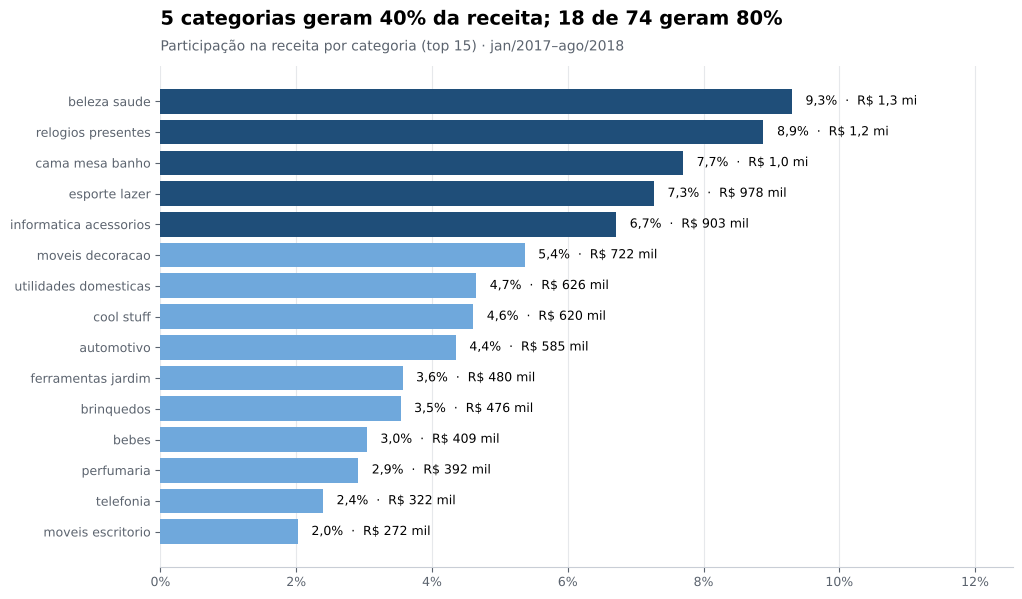

In [4]:
top = cat.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.5))
cores = [COLORS["primary"] if i >= len(top) - 5 else COLORS["secondary"] for i in range(len(top))]
ax.barh(top.index.str.replace("_", " "), top["participacao"], color=cores)
for y, (v, r) in enumerate(zip(top["participacao"], top["receita"])):
    ax.text(v + 0.002, y, f"{pct(v)}  ·  {brl_short(r)}", va="center", fontsize=9)
ax.set_title(f"5 categorias geram 40% da receita; {n80} de {len(cat)} geram 80%")
subtitle(ax, "Participação na receita por categoria (top 15) · jan/2017–ago/2018")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
axis_pct(ax, "x")
ax.set_xlim(0, top["participacao"].max() * 1.35)
save(fig, "07_categorias_participacao")
plt.show()

## 2. Categorias: quem está puxando o crescimento

In [5]:
def receita_periodo(ini, fim):
    p = items[(items["month"] >= ini) & (items["month"] <= fim)]
    return p.groupby("product_category_name")["price"].sum()

g = pd.DataFrame({"jan_ago_17": receita_periodo("2017-01-01", "2017-08-01"),
                  "jan_ago_18": receita_periodo("2018-01-01", "2018-08-01")}).fillna(0)
g["crescimento"] = g["jan_ago_18"] / g["jan_ago_17"] - 1
g["participacao_18"] = g["jan_ago_18"] / g["jan_ago_18"].sum()
g["receita_incremental"] = g["jan_ago_18"] - g["jan_ago_17"]
g["contrib_crescimento"] = g["receita_incremental"] / g["receita_incremental"].sum()
cresc_total = g["jan_ago_18"].sum() / g["jan_ago_17"].sum() - 1
g20 = g.sort_values("jan_ago_18", ascending=False).head(20)
print(f"Crescimento médio da empresa (jan–ago 18 vs 17): {pct(cresc_total)}")
g20[["jan_ago_17", "jan_ago_18", "crescimento", "participacao_18", "contrib_crescimento"]]

Crescimento médio da empresa (jan–ago 18 vs 17): 138,3%


,jan_ago_17,jan_ago_18,crescimento,participacao_18,contrib_crescimento
product_category_name,,,,,
beleza_saude,"247,457.95","770,002.81",2.11,0.10,0.12
relogios_presentes,"206,284.44","708,305.95",2.43,0.10,0.12
cama_mesa_banho,"259,621.24","537,514.13",1.07,0.07,0.07
esporte_lazer,"224,596.75","530,182.18",1.36,0.07,0.07
informatica_acessorios,"219,638.68","502,432.09",1.29,0.07,0.07
utilidades_domesticas,"131,132.61","397,688.06",2.03,0.05,0.06
moveis_decoracao,"180,301.14","385,312.01",1.14,0.05,0.05
automotivo,"128,278.06","346,632.44",1.70,0.05,0.05
bebes,"70,328.57","256,086.70",2.64,0.03,0.04


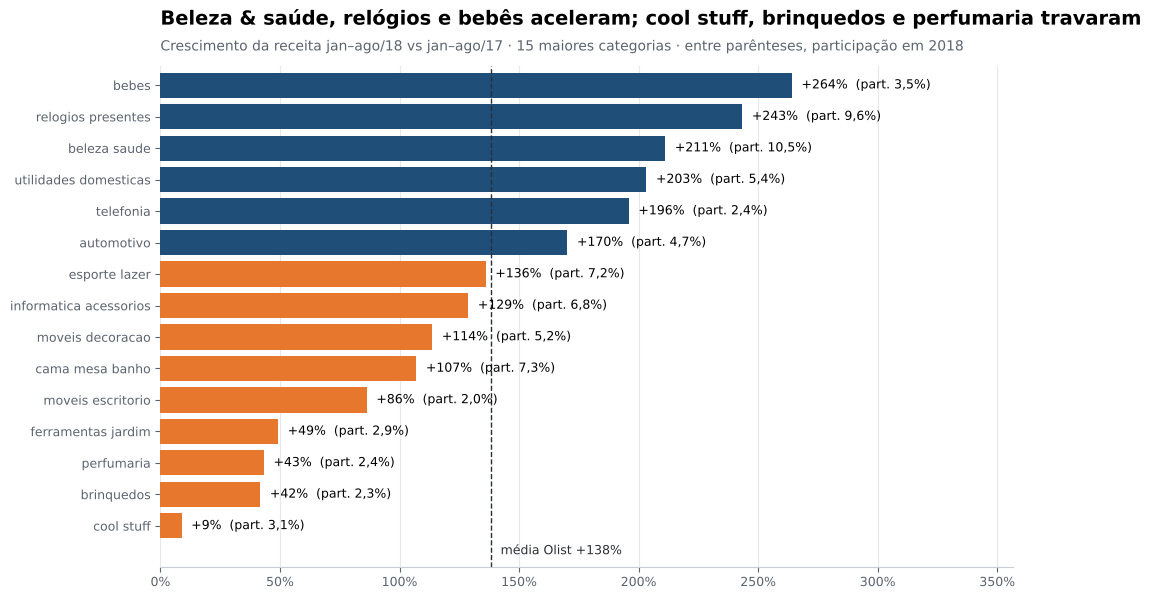

In [6]:
g15 = g.sort_values("jan_ago_18", ascending=False).head(15).sort_values("crescimento")
fig, ax = plt.subplots(figsize=(11, 6.5))
cores = np.where(g15["crescimento"] > cresc_total, COLORS["primary"], COLORS["accent"])
ax.barh(g15.index.str.replace("_", " "), g15["crescimento"], color=cores)
for y, (v, sh) in enumerate(zip(g15["crescimento"], g15["participacao_18"])):
    ax.text(v + 0.04, y, f"+{v*100:.0f}%  (part. {pct(sh)})", va="center", fontsize=9)
ax.axvline(cresc_total, color=COLORS["dark"], ls="--", lw=1)
ax.text(cresc_total + 0.04, -0.9, f"média Olist +{cresc_total*100:.0f}%", fontsize=9, color=COLORS["dark"])
ax.set_title("Beleza & saúde, relógios e bebês aceleram; cool stuff, brinquedos e perfumaria travaram")
subtitle(ax, "Crescimento da receita jan–ago/18 vs jan–ago/17 · 15 maiores categorias · entre parênteses, participação em 2018")
axis_pct(ax, "x")
ax.set_xlim(0, g15["crescimento"].max() * 1.35)
ax.set_ylim(-1.3, len(g15) - 0.4)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
save(fig, "08_categorias_crescimento")
plt.show()

In [7]:
contrib = g.sort_values("receita_incremental", ascending=False)
print("Categorias que mais adicionaram receita (jan–ago 18 vs 17):")
for nome, r in contrib.head(5).iterrows():
    print(f"  {nome:<25} +{brl(r['receita_incremental'])}  ({pct(r['contrib_crescimento'])} do crescimento)")
print(f"Top 5 explicam {pct(contrib['contrib_crescimento'].head(5).sum())} do crescimento")

Categorias que mais adicionaram receita (jan–ago 18 vs 17):
  beleza_saude              +R$ 522.545  (12,3% do crescimento)
  relogios_presentes        +R$ 502.022  (11,8% do crescimento)
  esporte_lazer             +R$ 305.585  (7,2% do crescimento)
  informatica_acessorios    +R$ 282.793  (6,6% do crescimento)
  cama_mesa_banho           +R$ 277.893  (6,5% do crescimento)
Top 5 explicam 44,4% do crescimento


**Leitura:**
* **Motores do crescimento:** beleza & saúde (+211%), relógios & presentes (+243%), utilidades domésticas
  (+203%), bebês (+264%) e telefonia (+196%) crescem acima da média. Beleza & saúde e relógios, sozinhas,
  explicam cerca de um quarto da receita incremental.
* **Categorias travadas:** cool stuff (+9%), perfumaria (+43%), brinquedos (+42%) e ferramentas & jardim
  (+49%) crescem bem abaixo da média – perdem relevância no mix e merecem diagnóstico (sortimento, preço,
  sellers).

## 3. Regiões: concentração no Sudeste

In [8]:
uf = items.groupby("customer_state").agg(
    receita=("price", "sum"), frete=("freight_value", "sum"),
    pedidos=("order_id", "nunique"), clientes=("customer_unique_id", "nunique"))
uf["participacao"] = uf["receita"] / R
uf["populacao"] = uf.index.map(IBGE_POP_2018)
uf["regiao"] = uf.index.map(UF_REGIAO)
uf["ticket_medio"] = uf["receita"] / uf["pedidos"]
uf["receita_por_mil_hab"] = uf["receita"] / uf["populacao"] * 1000
uf["pedidos_100k_hab"] = uf["pedidos"] / uf["populacao"] * 1e5
uf["frete_sobre_receita"] = uf["frete"] / uf["receita"]
uf = uf.sort_values("receita", ascending=False)
uf

,receita,frete,pedidos,clientes,participacao,populacao,regiao,ticket_medio,receita_por_mil_hab,pedidos_100k_hab,frete_sobre_receita
customer_state,,,,,,,,,,,
SP,"5,150,778.70","712,453.96",41021,39648,0.38,45538936,Sudeste,125.56,113.11,90.08,0.14
RJ,"1,802,436.24","303,113.40",12654,12200,0.13,17159960,Sudeste,142.44,105.04,73.74,0.17
MG,"1,568,855.98","268,790.09",11457,11098,0.12,21040662,Sudeste,136.93,74.56,54.45,0.17
RS,"739,357.46","134,277.30",5395,5213,0.05,11329605,Sul,137.04,65.26,47.62,0.18
PR,"674,867.55","116,834.34",4962,4805,0.05,11348937,Sul,136.01,59.47,43.72,0.17
SC,"516,340.22","89,182.76",3590,3493,0.04,7075494,Sul,143.83,72.98,50.74,0.17
BA,"506,214.78","99,698.54",3340,3240,0.04,14812617,Nordeste,151.56,34.17,22.55,0.20
DF,"299,842.68","50,284.42",2114,2051,0.02,2974703,Centro-Oeste,141.84,100.80,71.07,0.17
GO,"286,886.07","52,503.63",1990,1927,0.02,6921161,Centro-Oeste,144.16,41.45,28.75,0.18


In [9]:
reg = uf.groupby("regiao").agg(receita=("receita", "sum"), frete=("frete", "sum"),
                               pedidos=("pedidos", "sum"), populacao=("populacao", "sum"))
reg["% receita"] = reg["receita"] / reg["receita"].sum()
reg["% população"] = reg["populacao"] / reg["populacao"].sum()
reg["índice de penetração"] = reg["% receita"] / reg["% população"]
reg["ticket_medio"] = reg["receita"] / reg["pedidos"]
reg["receita_por_mil_hab"] = reg["receita"] / reg["populacao"] * 1000
reg["frete_sobre_receita"] = reg["frete"] / reg["receita"]
reg = reg.sort_values("receita", ascending=False)
reg[["% receita", "% população", "índice de penetração", "receita_por_mil_hab", "ticket_medio", "frete_sobre_receita"]]

,% receita,% população,índice de penetração,receita_por_mil_hab,ticket_medio,frete_sobre_receita
regiao,,,,,,
Sudeste,0.65,0.42,1.55,100.27,130.98,0.15
Sul,0.14,0.14,1.01,64.88,138.42,0.18
Nordeste,0.11,0.27,0.42,26.99,165.25,0.22
Centro-Oeste,0.06,0.08,0.83,53.43,150.47,0.18
Norte,0.02,0.09,0.28,18.29,181.96,0.23


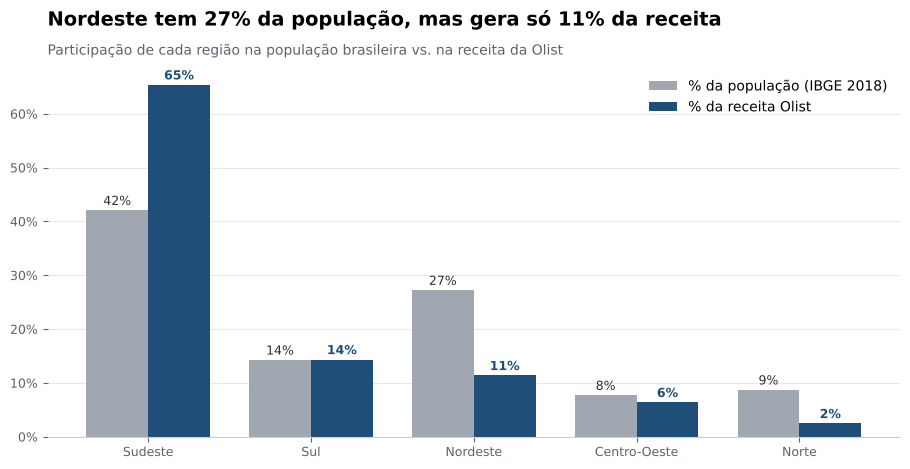

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(reg))
w = 0.38
ax.bar(x - w/2, reg["% população"], w, color=COLORS["neutral"], label="% da população (IBGE 2018)")
ax.bar(x + w/2, reg["% receita"], w, color=COLORS["primary"], label="% da receita Olist")
for i, (p, r) in enumerate(zip(reg["% população"], reg["% receita"])):
    ax.text(i - w/2, p + 0.01, pct(p, 0), ha="center", fontsize=9, color=COLORS["dark"])
    ax.text(i + w/2, r + 0.01, pct(r, 0), ha="center", fontsize=9, color=COLORS["primary"], weight="bold")
ax.set_xticks(x, reg.index)
axis_pct(ax)
ax.legend(loc="upper right")
ax.set_title("Nordeste tem 27% da população, mas gera só 11% da receita")
subtitle(ax, "Participação de cada região na população brasileira vs. na receita da Olist")
save(fig, "09_regioes_populacao_receita")
plt.show()

### Penetração por UF (dado externo IBGE)

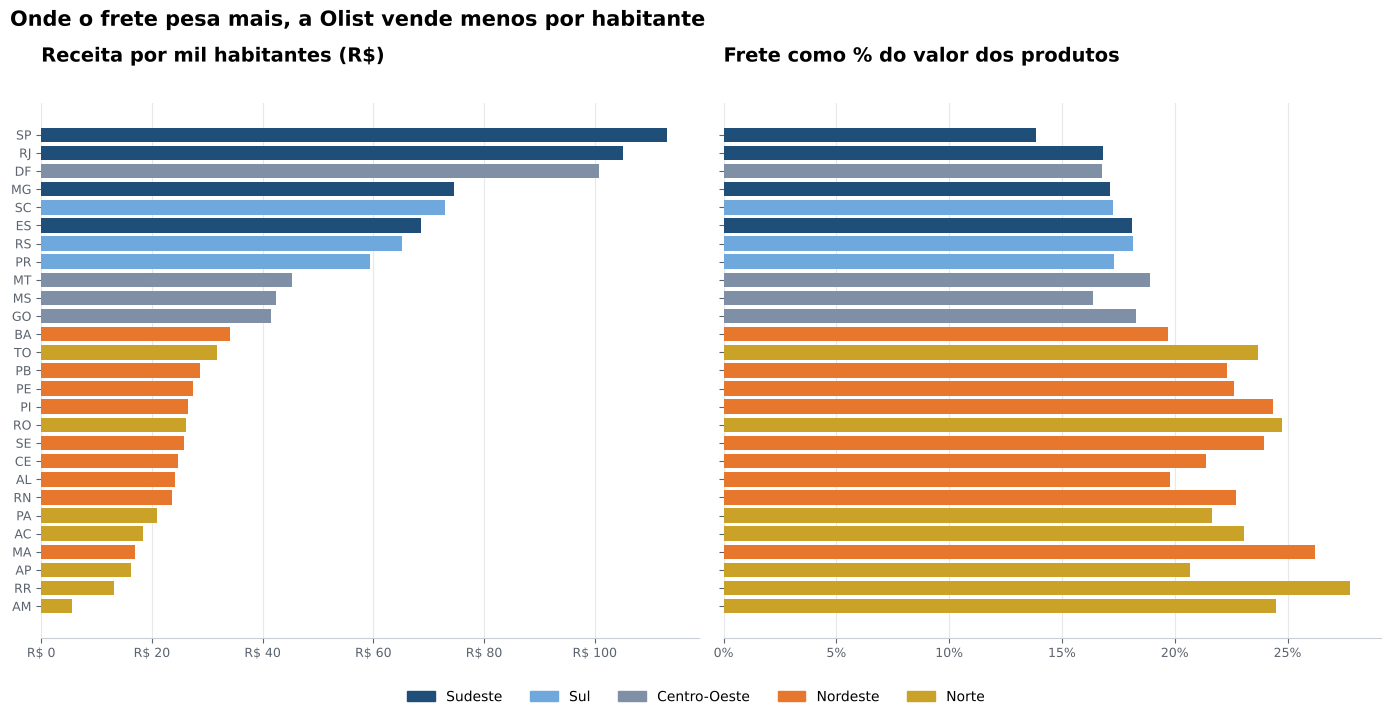

Correlação (Spearman) entre receita/hab e peso do frete nas 27 UFs: -0.83


In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
u = uf.sort_values("receita_por_mil_hab")
cor_reg = {"Sudeste": COLORS["primary"], "Sul": COLORS["secondary"], "Centro-Oeste": "#7E8FA6",
           "Nordeste": COLORS["accent"], "Norte": "#C9A227"}
c = u["regiao"].map(cor_reg)
ax1.barh(u.index, u["receita_por_mil_hab"], color=c)
ax1.set_title("Receita por mil habitantes (R$)")
ax1.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda x, p: f"R$ {x:.0f}"))
ax1.grid(axis="y", visible=False); ax1.grid(axis="x", visible=True)
ax2.barh(u.index, u["frete_sobre_receita"], color=c)
ax2.set_title("Frete como % do valor dos produtos")
axis_pct(ax2, "x")
ax2.grid(axis="y", visible=False); ax2.grid(axis="x", visible=True)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=v, label=k) for k, v in cor_reg.items()], loc="lower center",
           ncol=5, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Onde o frete pesa mais, a Olist vende menos por habitante", x=0.01, ha="left",
             fontsize=15, weight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "10_penetracao_frete_uf")
plt.show()
corr = uf[["receita_por_mil_hab", "frete_sobre_receita"]].corr(method="spearman").iloc[0, 1]
print(f"Correlação (Spearman) entre receita/hab e peso do frete nas 27 UFs: {corr:.2f}")

**Leitura:**
* **Concentração:** Sudeste = 65% da receita (só SP = 38%). Sul e Sudeste juntos somam ~80%.
* **Sub-penetração do Norte/Nordeste:** o Nordeste tem 27% da população e apenas 11% da receita
  (índice de penetração ≈ 0,4). A cada mil habitantes, o Sudeste gera R$ 100 de receita (SP: R$ 113); o Nordeste, R$ 27.
* **O frete é a barreira:** no Norte/Nordeste o frete equivale a 20–28% do valor dos produtos, contra 14% em
  SP – e as UFs onde o frete pesa mais são justamente as de menor receita por habitante (correlação
  fortemente negativa). O ticket médio é **maior** nessas regiões: o cliente só compra quando o item é caro
  o suficiente para "compensar" o frete.

## 4. Municípios

In [12]:
cid = items.groupby(["customer_city", "customer_state"]).agg(
    receita=("price", "sum"), pedidos=("order_id", "nunique")).sort_values("receita", ascending=False)
cid["participacao"] = cid["receita"] / R
cid["acumulado"] = cid["participacao"].cumsum()
n_mun = len(cid)
print(f"{fmt_int(n_mun)} municípios com vendas | top 10 = {pct(cid['participacao'].head(10).sum())} da receita | "
      f"municípios para 50% da receita: {(cid['acumulado'] < 0.5).sum() + 1}")
cid.head(10)

4.296 municípios com vendas | top 10 = 33,8% da receita | municípios para 50% da receita: 45


,,receita,pedidos,participacao,acumulado
customer_city,customer_state,,,,
sao paulo,SP,"1,893,086.01",15257,0.14,0.14
rio de janeiro,RJ,"979,657.95",6771,0.07,0.21
belo horizonte,MG,"349,414.68",2726,0.03,0.24
brasilia,DF,"299,158.99",2105,0.02,0.26
curitiba,PR,"207,590.98",1496,0.02,0.28
campinas,SP,"186,474.27",1416,0.01,0.29
porto alegre,RS,"185,973.15",1364,0.01,0.30
salvador,BA,"180,735.72",1234,0.01,0.32
guarulhos,SP,"142,498.48",1166,0.01,0.33


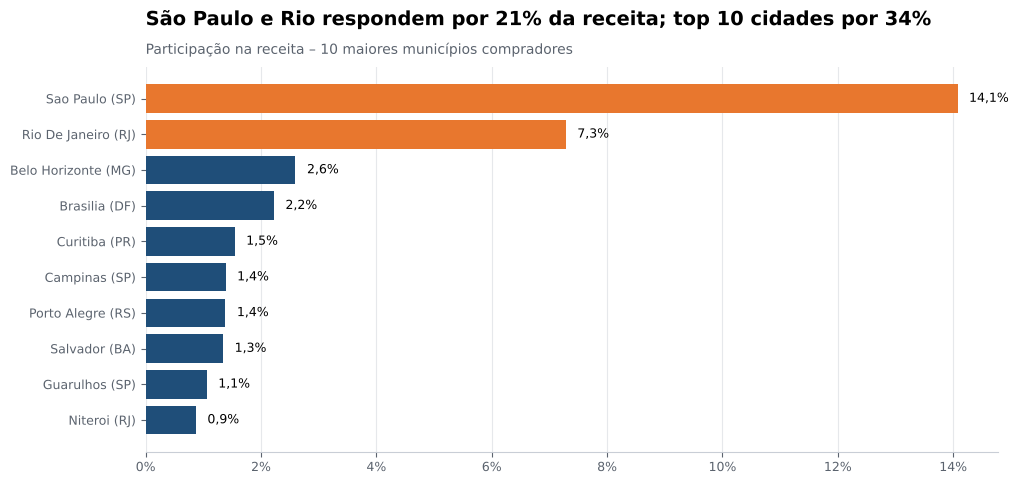

In [13]:
t10 = cid.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
labels = [f"{c.title()} ({u})" for c, u in t10.index]
ax.barh(labels, t10["participacao"], color=[COLORS["accent"] if i >= 8 else COLORS["primary"]
                                           for i in range(len(t10))])
for y, v in enumerate(t10["participacao"]):
    ax.text(v + 0.002, y, pct(v), va="center", fontsize=9)
ax.set_title("São Paulo e Rio respondem por 21% da receita; top 10 cidades por 34%")
subtitle(ax, "Participação na receita – 10 maiores municípios compradores")
axis_pct(ax, "x")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
save(fig, "11_municipios_top10")
plt.show()

## 5. Crescimento por região

In [14]:
rg = pd.DataFrame({
    "jan_ago_17": items[(items["month"] >= "2017-01-01") & (items["month"] <= "2017-08-01")].groupby("customer_region")["price"].sum(),
    "jan_ago_18": items[(items["month"] >= "2018-01-01") & (items["month"] <= "2018-08-01")].groupby("customer_region")["price"].sum(),
})
rg["crescimento"] = rg["jan_ago_18"] / rg["jan_ago_17"] - 1
rg.sort_values("crescimento", ascending=False)

,jan_ago_17,jan_ago_18,crescimento
customer_region,,,
Sudeste,"1,951,500.41","4,866,432.42",1.49
Centro-Oeste,"202,142.92","458,089.53",1.27
Sul,"463,687.65","1,047,455.76",1.26
Nordeste,"367,318.85","804,463.45",1.19
Norte,"96,200.98","164,596.25",0.71


## Conclusões do notebook
1. **Mix concentrado:** 5 categorias = 40% da receita; 18 de 74 = 80%.
2. **Motores:** beleza & saúde, relógios & presentes, utilidades domésticas e bebês crescem 2–3x a média.
   **Travadas:** cool stuff, perfumaria, brinquedos e ferramentas & jardim.
3. **Geografia concentrada:** Sudeste 65% da receita; São Paulo (capital) sozinha 14%.
4. **Concentração aumentando:** o Sudeste cresceu +149% (jan–ago 18 vs 17), acima de Nordeste (+119%) e
   Norte (+71%) – a dependência do eixo SP-RJ-MG está aumentando, não diminuindo.
5. **Oportunidade regional:** Norte/Nordeste têm 36% da população e 14% da receita; o frete
   (20–28% do valor do produto) é a principal barreira – espaço para logística regional e sellers locais.

➡️ Próximo: `04_top_performers.ipynb`